# Module 12 — Unsupervised Learning

**Applied exercises only** · ISLP, Chapter 12

**Printed textbook pages:** 554–556 (exercise starting pages)  
**Included:** 7 applied exercises; original exercise numbers retained.

In [1]:
# Common imports: run this cell once before starting the exercises.
# Runs in the project's .venv. USArrests is loaded with statsmodels' get_rdataset (as in the lab);
# Ch12Ex13.csv (from the book website) is stored next to this notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from scipy.stats import ttest_ind
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from statsmodels.datasets import get_rdataset
from statsmodels.stats.multitest import multipletests
from ISLP import load_data

rng = np.random.default_rng(1)
USArrests = get_rdataset("USArrests").data
print(USArrests.shape)

(50, 4)


---

## Exercise 7 · Applied

**Textbook: printed page 554**

In this chapter, we mentioned the use of correlation-based distance
and Euclidean distance as dissimilarity measures for hierarchical clustering. It turns out that these two measures are almost equivalent: if
each observation has been centered to have mean zero and standard
deviation one, and if we let rij denote the correlation between the ith
and jth observations, then the quantity 1 −rij is proportional to the
squared Euclidean distance between the ith and jth observations.
On the USArrests data, show that this proportionality holds.

**Hint:** The Euclidean distance can be calculated using the `pairwise_distances()` function from the `sklearn.metrics` module, and correlations can be calculated using the `np.corrcoef()` function.

d_ij^2 / (1 - r_ij): mean = 8.000000, min = 8.000000, max = 8.000000
Theory: d_ij^2 = 2p (1 - r_ij) with p = 4, i.e. the constant is 8


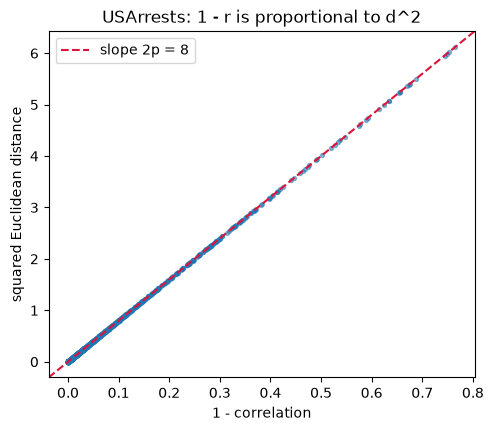

In [2]:
# Exercise 7
# Standardise each *observation* (row) to mean 0, SD 1 across its four measurements.
X7 = USArrests.to_numpy(dtype=float)
Z = (X7 - X7.mean(axis=1, keepdims=True)) / X7.std(axis=1, keepdims=True)

D2 = pairwise_distances(Z) ** 2            # squared Euclidean distances between states
R = np.corrcoef(Z)                         # correlations between states (rows)
iu = np.triu_indices_from(D2, k=1)
ratio = D2[iu] / (1 - R[iu])
print(f"d_ij^2 / (1 - r_ij): mean = {ratio.mean():.6f}, min = {ratio.min():.6f}, max = {ratio.max():.6f}")
print(f"Theory: d_ij^2 = 2p (1 - r_ij) with p = {Z.shape[1]}, i.e. the constant is {2 * Z.shape[1]}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(1 - R[iu], D2[iu], s=8, alpha=0.5)
ax.axline((0, 0), slope=2 * Z.shape[1], color="crimson", ls="--", label="slope 2p = 8")
ax.set(xlabel="1 - correlation", ylabel="squared Euclidean distance", title="USArrests: 1 - r is proportional to d^2")
ax.legend()
plt.show()

**Observations / conclusions**

After standardising each state's four measurements to mean 0 and SD 1, the ratio $d_{ij}^2 / (1 - r_{ij})$ equals **exactly 8** for all 1,225 pairs of states.
The reason: for standardised vectors of length p, $\lVert z_i - z_j\rVert^2 = \sum z_i^2 + \sum z_j^2 - 2\sum z_i z_j = p + p - 2p\,r_{ij} = 2p(1 - r_{ij})$, and p = 4. So correlation-based distance and squared Euclidean distance give the same clustering in this setting.

---

## Exercise 8 · Applied

**Textbook: printed page 554**

In Section 12.2.3, a formula for calculating PVE was given in Equation 12.10. We also saw that the PVE can be obtained using the
explained_variance_ratio_ attribute of a fitted PCA() estimator.
On the USArrests data, calculate PVE in two ways:

### Exercise 8(a)

Using the explained_variance_ratio_ output of the fitted PCA()
estimator, as was done in Section 12.2.3.

In [3]:
# Exercise 8(a)
X8 = StandardScaler().fit_transform(USArrests)
pca8 = PCA().fit(X8)
pve_a = pca8.explained_variance_ratio_
print("PVE from explained_variance_ratio_:", pve_a.round(6))

PVE from explained_variance_ratio_: [0.62006  0.247441 0.089141 0.043358]


### Exercise 8(b)

By applying Equation 12.10 directly. The loadings are stored
as the components_ attribute of the fitted PCA() estimator. Use
those loadings in Equation 12.10 to obtain the PVE.
These two approaches should give the same results.

**Hint:** You will only obtain the same results in (a) and (b) if the same
data is used in both cases. For instance, if in (a) you performed PCA()
using centered and scaled variables, then you must center and scale
the variables before applying Equation 12.10 in (b).

In [4]:
# Exercise 8(b)
# Equation 12.10: PVE_m = sum_i (sum_j phi_jm x_ij)^2 / sum_i sum_j x_ij^2, using the same centred/scaled data.
phi = pca8.components_.T                      # p x M loadings
scores = X8 @ phi
pve_b = (scores ** 2).sum(axis=0) / (X8 ** 2).sum()
print("PVE from Equation 12.10:            ", pve_b.round(6))
print("Max |difference|:", np.abs(pve_a - pve_b).max())

PVE from Equation 12.10:             [0.62006  0.247441 0.089141 0.043358]
Max |difference|: 1.1102230246251565e-16


**Observations / conclusions**

Using PCA on the scaled USArrests data, both methods give the same PVE: **62.0%, 24.7%, 8.9% and 4.3%** for PC1–PC4 (maximum difference about 1e-16). Equation 12.10 matches `explained_variance_ratio_` exactly, provided it's applied to the same centred and scaled data the PCA was fitted on.

---

## Exercise 9 · Applied

**Textbook: printed page 554**

Consider the USArrests data. We will now perform hierarchical clustering on the states.

### Exercise 9(a)

Using hierarchical clustering with complete linkage and Euclidean distance, cluster the states.

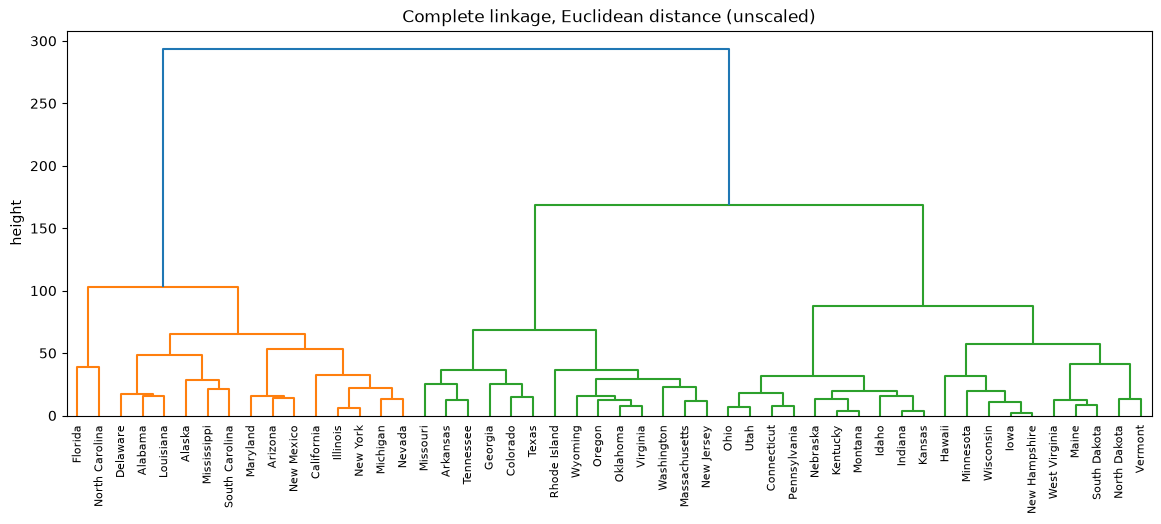

In [5]:
# Exercise 9(a)
hc_raw = linkage(USArrests.to_numpy(dtype=float), method="complete", metric="euclidean")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(hc_raw, labels=USArrests.index.to_list(), leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set(title="Complete linkage, Euclidean distance (unscaled)", ylabel="height")
plt.show()

### Exercise 9(b)

Cut the dendrogram at a height that results in three distinct
clusters. Which states belong to which clusters?

In [6]:
# Exercise 9(b)
cut_raw = pd.Series(fcluster(hc_raw, t=3, criterion="maxclust"), index=USArrests.index, name="cluster")
for k, states in cut_raw.groupby(cut_raw):
    print(f"Cluster {k} ({len(states)} states): {', '.join(states.index)}\n")
print("Cluster means (unscaled data):")
display(USArrests.groupby(cut_raw).mean().round(1))

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin

Cluster means (unscaled data):


,Murder,Assault,UrbanPop,Rape
cluster,,,,
1,11.8,272.6,68.3,28.4
2,8.2,173.3,70.6,22.8
3,4.3,87.6,59.8,14.4


### Exercise 9(c)

Hierarchically cluster the states using complete linkage and Euclidean distance, after scaling the variables to have standard deviation one.

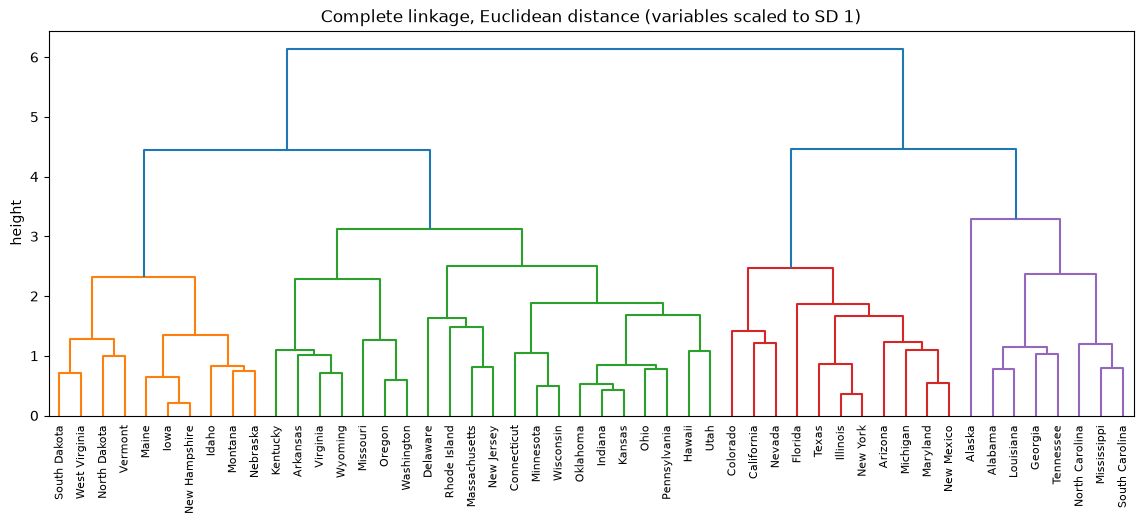

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming

Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee



In [7]:
# Exercise 9(c)
X_scaled = StandardScaler().fit_transform(USArrests)
hc_sc = linkage(X_scaled, method="complete", metric="euclidean")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(hc_sc, labels=USArrests.index.to_list(), leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set(title="Complete linkage, Euclidean distance (variables scaled to SD 1)", ylabel="height")
plt.show()
cut_sc = pd.Series(fcluster(hc_sc, t=3, criterion="maxclust"), index=USArrests.index, name="cluster")
for k, states in cut_sc.groupby(cut_sc):
    print(f"Cluster {k} ({len(states)} states): {', '.join(states.index)}\n")

### Exercise 9(d)

What effect does scaling the variables have on the hierarchical
clustering obtained? In your opinion, should the variables be
scaled before the inter-observation dissimilarities are computed?
Provide a justification for your answer.

In [8]:
# Exercise 9(d)
print("Variable standard deviations (unscaled):")
print(USArrests.std().round(2).to_string())
print("\nCross-tabulation of 3-cluster solutions (rows = unscaled, columns = scaled):")
display(pd.crosstab(cut_raw.rename("unscaled"), cut_sc.rename("scaled")))
print(f"Adjusted Rand index between the two solutions: {adjusted_rand_score(cut_raw, cut_sc):.3f}")
print("\nCluster means, scaled solution:")
display(USArrests.groupby(cut_sc).mean().round(1))

Variable standard deviations (unscaled):
Murder       4.36
Assault     83.34
UrbanPop    14.47
Rape         9.37

Cross-tabulation of 3-cluster solutions (rows = unscaled, columns = scaled):


scaled,1,2,3
unscaled,,,
1,1,9,6
2,10,2,2
3,20,0,0


Adjusted Rand index between the two solutions: 0.368

Cluster means, scaled solution:


,Murder,Assault,UrbanPop,Rape
cluster,,,,
1,5.0,116.5,63.8,16.3
2,11.1,264.1,79.1,32.6
3,14.1,252.8,53.5,24.5


**Observations / conclusions**

- **(a, b)** On the raw data, the three clusters (16 / 14 / 20 states) are essentially **high, medium and low `Assault`**, with cluster means of 273, 173 and 88. Cluster 1 includes Florida, North Carolina, California, New York and others. Cluster 3 contains the low-crime northern and rural states such as Iowa, Maine, North Dakota and Vermont.
- **(c)** After scaling each variable to SD 1, the clusters change a lot (31 / 11 / 8 states; adjusted Rand index vs the unscaled solution = 0.37). One cluster is low-crime states. A second (California, New York, Florida, Arizona, …) is **high-crime and highly urban**. A third (Mississippi, Georgia, the Carolinas, Alabama, …) has **high murder rates but low urbanisation**.
- **(d)** Without scaling, `Assault` (SD ≈ 83) dominates the Euclidean distance, because the other variables have SDs of 4–14. The clustering is then really a one-variable clustering on assault rate. The variables are in different units (arrests per 100,000 vs percent urban), so they **should be scaled**. Scaling lets all four contribute and produces more interpretable groups, such as separating urban from rural high-crime states.

---

## Exercise 10 · Applied

**Textbook: printed page 555**

In this problem, you will generate simulated data, and then perform
PCA and K-means clustering on the data.

### Exercise 10(a)

Generate a simulated data set with 20 observations in each of
three classes (i.e. 60 observations total), and 50 variables.

**Hint:** There are a number of functions in Python that you can
use to generate data. One example is the normal() method of
the random() function in numpy; the uniform() method is another
option. Be sure to add a mean shift to the observations in each
class so that there are three distinct classes.

In [9]:
# Exercise 10(a)
rng = np.random.default_rng(10)
X10 = rng.normal(size=(60, 50))
true_class = np.repeat([0, 1, 2], 20)
X10[true_class == 1, :] += 1.0                       # class 2: shift every variable up
X10[true_class == 2, :25] -= 1.0                     # class 3: shift the first 25 variables down
X10[true_class == 2, 25:] += 0.5
print(X10.shape)

(60, 50)


### Exercise 10(b)

Perform PCA on the 60 observations and plot the first two principal component score vectors. Use a different color to indicate
the observations in each of the three classes. If the three classes
appear separated in this plot, then continue on to part (c). If
not, then return to part (a) and modify the simulation so that
there is greater separation between the three classes. Do not
continue to part (c) until the three classes show at least some
separation in the first two principal component score vectors.

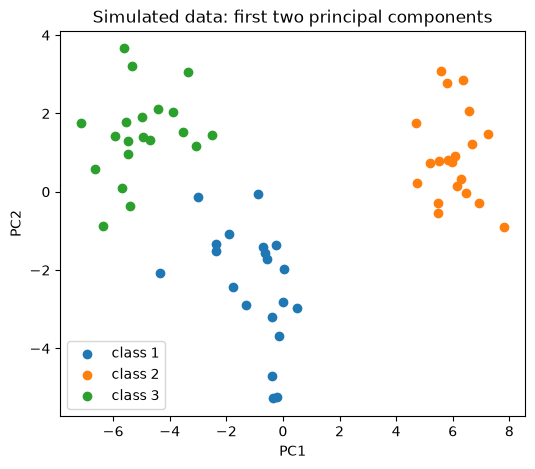

PVE of first two PCs: [0.31  0.062]


In [10]:
# Exercise 10(b)
pca10 = PCA().fit(X10)
pc = pca10.transform(X10)[:, :2]
fig, ax = plt.subplots(figsize=(6, 5))
for k, color in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    ax.scatter(pc[true_class == k, 0], pc[true_class == k, 1], color=color, label=f"class {k + 1}")
ax.set(xlabel="PC1", ylabel="PC2", title="Simulated data: first two principal components")
ax.legend()
plt.show()
print("PVE of first two PCs:", pca10.explained_variance_ratio_[:2].round(3))

### Exercise 10(c)

Perform K-means clustering of the observations with K = 3.
How well do the clusters that you obtained in K-means clustering compare to the true class labels?

**Hint:** You can use the pd.crosstab() function in Python to compare the true class labels to the class labels obtained by clustering. Be careful how you interpret the results: K-means clustering
will arbitrarily number the clusters, so you cannot simply check
whether the true class labels and clustering labels are the same.

In [11]:
# Exercise 10(c)
km3 = KMeans(n_clusters=3, n_init=20, random_state=0).fit(X10)
display(pd.crosstab(pd.Series(true_class + 1, name="true class"), pd.Series(km3.labels_, name="K-means cluster")))
print(f"Adjusted Rand index: {adjusted_rand_score(true_class, km3.labels_):.3f}")

K-means cluster,0,1,2
true class,,,
1,18,0,2
2,0,20,0
3,0,0,20


Adjusted Rand index: 0.902


### Exercise 10(d)

Perform K-means clustering with K = 2. Describe your results.

In [12]:
# Exercise 10(d)
km2 = KMeans(n_clusters=2, n_init=20, random_state=0).fit(X10)
display(pd.crosstab(pd.Series(true_class + 1, name="true class"), pd.Series(km2.labels_, name="K-means cluster")))

K-means cluster,0,1
true class,,
1,0,20
2,20,0
3,0,20


### Exercise 10(e)

Now perform K-means clustering with K = 4, and describe your
results.

In [13]:
# Exercise 10(e)
km4 = KMeans(n_clusters=4, n_init=20, random_state=0).fit(X10)
display(pd.crosstab(pd.Series(true_class + 1, name="true class"), pd.Series(km4.labels_, name="K-means cluster")))

K-means cluster,0,1,2,3
true class,,,,
1,2,0,18,0
2,0,20,0,0
3,12,0,0,8


### Exercise 10(f)

Now perform K-means clustering with K = 3 on the first two
principal component score vectors, rather than on the raw data.
That is, perform K-means clustering on the 60 × 2 matrix of
which the first column is the first principal component score
vector, and the second column is the second principal component
score vector. Comment on the results.

In [14]:
# Exercise 10(f)
km_pc = KMeans(n_clusters=3, n_init=20, random_state=0).fit(pc)
display(pd.crosstab(pd.Series(true_class + 1, name="true class"), pd.Series(km_pc.labels_, name="K-means on PC1-PC2")))
print(f"Adjusted Rand index: {adjusted_rand_score(true_class, km_pc.labels_):.3f}")

K-means on PC1-PC2,0,1,2
true class,,,
1,0,2,18
2,20,0,0
3,0,20,0


Adjusted Rand index: 0.902


### Exercise 10(g)

Using the StandardScaler() estimator, perform K-means clustering with K = 3 on the data after scaling each variable to have
standard deviation one. How do these results compare to those
obtained in (b)? Explain.

In [15]:
# Exercise 10(g)
X10_sc = StandardScaler().fit_transform(X10)
km_sc = KMeans(n_clusters=3, n_init=20, random_state=0).fit(X10_sc)
display(pd.crosstab(pd.Series(true_class + 1, name="true class"), pd.Series(km_sc.labels_, name="K-means (scaled)")))
print(f"Adjusted Rand index: {adjusted_rand_score(true_class, km_sc.labels_):.3f}")

K-means (scaled),0,1,2
true class,,,
1,19,0,1
2,0,20,0
3,0,0,20


Adjusted Rand index: 0.950


**Observations / conclusions**

I simulated three classes of 20 observations with 50 variables. Class 2 is shifted up by 1 on every variable. Class 3 is shifted down by 1 on the first 25 variables and up by 0.5 on the rest.
- **(b)** The first two PCs (31% + 6% of variance) clearly separate the three classes.
- **(c)** K = 3 recovers the classes almost perfectly: classes 2 and 3 are clustered exactly, and 2 of the 20 class-1 points go to the class-3 cluster (ARI = 0.90). The cluster numbers are arbitrary, so the comparison has to use a crosstab.
- **(d)** K = 2 keeps class 2 on its own and merges classes 1 and 3, which are the two closest in the full 50-dimensional space.
- **(e)** K = 4 keeps class 2 intact and mostly keeps class 1 together, but **splits class 3** into two clusters (12 and 8). Forcing an extra cluster just divides a real group.
- **(f)** K-means on just the first two PC scores performs as well as on the full data (ARI = 0.90). The PCs keep the between-class signal and discard mostly noise.
- **(g)** After scaling each variable to SD 1, K-means gets ARI = 0.95, with one misclassified point. Here all variables are already on the same scale (SD ≈ 1 plus the shifts), so scaling changes little. In this case it slightly sharpened the result, because no single variable dominates.

---

## Exercise 11 · Applied

**Textbook: printed page 556**

Write a Python function to perform matrix completion as in Algorithm 12.1, and as outlined in Section 12.5.2. In each iteration, the
function should keep track of the relative error, as well as the iteration count. Iterations should continue until the relative error is small
enough or until some maximum number of iterations is reached (set a
default value for this maximum number). Furthermore, there should
be an option to print out the progress in each iteration.
Test your function on the Boston data. First, standardize the features
to
have
mean
zero
and
standard
deviation
one
using
the
StandardScaler() function. Run an experiment where you randomly
leave out an increasing (and nested) number of observations from 5%
to 30%, in steps of 5%. Apply Algorithm 12.1 with M = 1, 2, . . . , 8.
Display the approximation error as a function of the fraction of observations that are missing, and the value of M, averaged over 10
repetitions of the experiment.

Iter 1: MSS = 0.2985, relative error = 6.995e-01
Iter 2: MSS = 0.2817, relative error = 1.684e-02
Iter 3: MSS = 0.2791, relative error = 2.617e-03
Iter 4: MSS = 0.2785, relative error = 6.684e-04
Iter 5: MSS = 0.2782, relative error = 2.351e-04
Iter 6: MSS = 0.2781, relative error = 9.955e-05


M,column means,1,2,3,4,5,6,7,8
fraction missing,,,,,,,,,
0.05,1.004,0.620,0.617,0.572,4.598,6.833,7.974,6.118,6.578
0.10,1.003,0.603,0.594,0.567,2.893,5.724,5.838,4.819,5.714
0.15,1.003,0.604,0.588,0.567,2.866,5.112,5.312,4.221,5.925
0.20,1.004,0.609,0.610,0.986,3.493,4.842,5.384,5.133,6.056
0.25,1.004,0.608,0.626,0.657,3.490,4.742,4.868,4.749,5.245
0.30,1.005,0.613,0.635,0.739,2.988,4.430,4.907,4.597,4.978


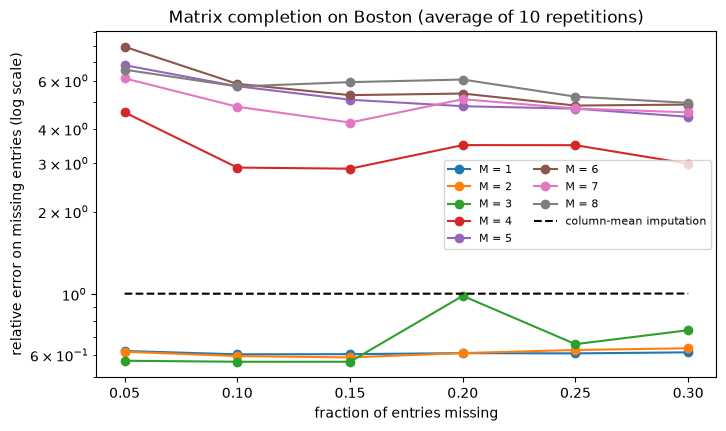

In [16]:
# Exercise 11
def low_rank(X, M):
    """Best rank-M approximation of X via the SVD."""
    U, D, Vt = np.linalg.svd(X, full_matrices=False)
    return (U[:, :M] * D[:M]) @ Vt[:M]

def matrix_complete(X_na, M=1, thresh=1e-7, max_iter=1000, verbose=False, approx=low_rank):
    """Algorithm 12.1 (ISLP Section 12.5.2): iterative low-rank matrix completion.

    X_na: array with np.nan for missing entries. Returns (completed matrix, number of iterations).
    """
    ismiss = np.isnan(X_na)
    Xhat = X_na.copy()
    Xhat[ismiss] = np.take(np.nanmean(X_na, axis=0), np.where(ismiss)[1])   # step 1: column means
    mss_old = np.mean(X_na[~ismiss] ** 2)
    mss0 = mss_old
    rel_err, it = 1.0, 0
    while rel_err > thresh and it < max_iter:
        it += 1
        Xapp = approx(Xhat, M)                                  # step 2(a)
        Xhat[ismiss] = Xapp[ismiss]                             # step 2(b)
        mss = np.mean((X_na[~ismiss] - Xapp[~ismiss]) ** 2)     # step 2(c)
        rel_err = (mss_old - mss) / mss0
        mss_old = mss
        if verbose:
            print(f"Iter {it}: MSS = {mss:.4f}, relative error = {rel_err:.3e}")
    return Xhat, it

Boston = load_data("Boston")
Xb = StandardScaler().fit_transform(Boston)
n_b, p_b = Xb.shape

# quick demonstration of the progress printout
demo = Xb.copy()
demo_mask = np.random.default_rng(0).random(demo.shape) < 0.1
demo[demo_mask] = np.nan
_ = matrix_complete(demo, M=3, verbose=True, max_iter=6)

fractions = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
Ms = range(1, 9)
reps = 10
errors = np.zeros((reps, len(fractions), len(Ms)))
baseline = np.zeros((reps, len(fractions)))       # error of simply imputing column means
for r in range(reps):
    order = np.random.default_rng(100 + r).permutation(n_b * p_b)    # nested missing sets
    for fi, frac in enumerate(fractions):
        miss = np.zeros(n_b * p_b, dtype=bool)
        miss[order[: int(round(frac * n_b * p_b))]] = True
        miss = miss.reshape(n_b, p_b)
        X_na = Xb.copy()
        X_na[miss] = np.nan
        col_means = np.take(np.nanmean(X_na, axis=0), np.where(miss)[1])
        baseline[r, fi] = np.sum((col_means - Xb[miss]) ** 2) / np.sum(Xb[miss] ** 2)
        for mi, M in enumerate(Ms):
            Xhat, _ = matrix_complete(X_na, M=M)
            # approximation error on the held-out entries, relative to their total sum of squares
            errors[r, fi, mi] = np.sum((Xhat[miss] - Xb[miss]) ** 2) / np.sum(Xb[miss] ** 2)

err_mean = pd.DataFrame(errors.mean(axis=0), index=pd.Index(fractions, name="fraction missing"),
                        columns=pd.Index(list(Ms), name="M"))
err_mean.insert(0, "column means", baseline.mean(axis=0))
display(err_mean.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for M in Ms:
    ax.plot(fractions, err_mean[M], marker="o", label=f"M = {M}")
ax.plot(fractions, err_mean["column means"], color="black", ls="--", label="column-mean imputation")
ax.set_yscale("log")
ax.set(xlabel="fraction of entries missing", ylabel="relative error on missing entries (log scale)",
       title="Matrix completion on Boston (average of 10 repetitions)")
ax.legend(ncol=2, fontsize=8)
plt.show()

**Observations / conclusions**

`matrix_complete()` implements Algorithm 12.1. It starts from column means, then repeatedly (a) computes the rank-M SVD approximation, (b) fills the missing entries from it, and (c) tracks the observed-entry MSS and relative error. It stops at `thresh` or `max_iter`, and prints progress when `verbose=True`.

On standardised Boston data (13 variables), with nested missing sets from 5% to 30% and 10 repetitions:
- Imputing **column means** gives relative error ≈ 1.0 on the missing entries.
- **M = 1–3** do much better, with relative error ≈ **0.57–0.63**: about 40% of the missing variance is recovered. M = 3 is best at low missingness (0.57 at 5–15% missing), and M = 1–2 are more stable as missingness grows. M = 3 occasionally fails to converge cleanly, e.g. 0.99 at 20% missing.
- **M ≥ 4 is much worse**: errors of 3–8, *worse than mean imputation*. These runs hit the 1,000-iteration limit. With a rank close to the number of columns, the low-rank model has enough freedom to fit the observed entries while the missing entries drift to extreme values. That is overfitting, and a reason to choose a small M or use a soft-thresholded (penalised) version of the algorithm.

Error changes only modestly with the fraction missing for small M. The choice of M matters far more than the amount of missing data in this range.

---

## Exercise 12 · Applied

**Textbook: printed page 556**

In Section 12.5.2, Algorithm 12.1 was implemented using the
svd() function from the np.linalg module. However, given the connection between the svd() function and the PCA() estimator highlighted in the lab, we could have instead implemented the algorithm
using PCA().
Write a function to implement Algorithm 12.1 that makes use of PCA()
rather than svd().

In [17]:
# Exercise 12
def low_rank_pca(X, M):
    """Rank-M approximation using sklearn's PCA (which centres the columns first)."""
    pca = PCA(n_components=M).fit(X)
    return pca.inverse_transform(pca.transform(X))

def matrix_complete_pca(X_na, M=1, thresh=1e-7, max_iter=1000, verbose=False):
    """Algorithm 12.1 implemented with PCA() instead of np.linalg.svd()."""
    return matrix_complete(X_na, M=M, thresh=thresh, max_iter=max_iter, verbose=verbose, approx=low_rank_pca)

# Compare with the SVD version on one missing-data pattern (20% missing)
miss = np.random.default_rng(5).random(Xb.shape) < 0.2
X_na = Xb.copy()
X_na[miss] = np.nan
rows = []
for M in range(1, 9):
    xs, it_s = matrix_complete(X_na, M=M)
    xp, it_p = matrix_complete_pca(X_na, M=M)
    rows.append({"M": M,
                 "SVD error": np.sum((xs[miss] - Xb[miss]) ** 2) / np.sum(Xb[miss] ** 2),
                 "PCA error": np.sum((xp[miss] - Xb[miss]) ** 2) / np.sum(Xb[miss] ** 2),
                 "SVD iters": it_s, "PCA iters": it_p})
pd.DataFrame(rows).set_index("M").round(4)

,SVD error,PCA error,SVD iters,PCA iters
M,,,,
1,0.6022,0.6049,12,12
2,0.5677,0.5703,18,18
3,0.5956,0.6024,44,46
4,9.9817,10.1562,1000,1000
5,8.6836,8.7896,1000,1000
6,8.5308,8.5648,1000,1000
7,7.1145,7.1657,1000,1000
8,6.9915,7.0328,1000,1000


**Observations / conclusions**

`matrix_complete_pca()` uses the same loop but computes the rank-M approximation with `PCA(n_components=M)` (`transform` then `inverse_transform`) instead of `np.linalg.svd`. Unlike the plain SVD version, `PCA()` **centres the columns first** and adds the means back. Because the Boston data are already standardised, the column means are ~0 and the two versions give almost identical errors and iteration counts: for 20% missing, M = 2 gives 0.568 (SVD) vs 0.570 (PCA). The small differences come from re-centring at each iteration, after the imputed values shift the column means slightly. Both versions show the same overfitting for M ≥ 4.

---

## Exercise 13 · Applied

**Textbook: printed page 556**

On the course materials, there is a gene expression data set (Ch12Ex13.csv) that consists of 40 tissue samples with
measurements on 1,000 genes. The first 20 samples are from healthy
patients, while the second 20 are from a diseased group.

### Exercise 13(a)

Load in the data using pd.read_csv(). You will need to select
header = None.

In [18]:
# Exercise 13(a)
genes = pd.read_csv("Ch12Ex13.csv", header=None)
print(genes.shape, "(rows = genes, columns = tissue samples)")
samples = genes.T.to_numpy()            # 40 samples x 1000 genes
group = np.repeat(["healthy", "diseased"], 20)

(1000, 40) (rows = genes, columns = tissue samples)


### Exercise 13(b)

Apply hierarchical clustering to the samples using correlationbased distance, and plot the dendrogram. Do the genes separate
the samples into the two groups? Do your results depend on the
type of linkage used?

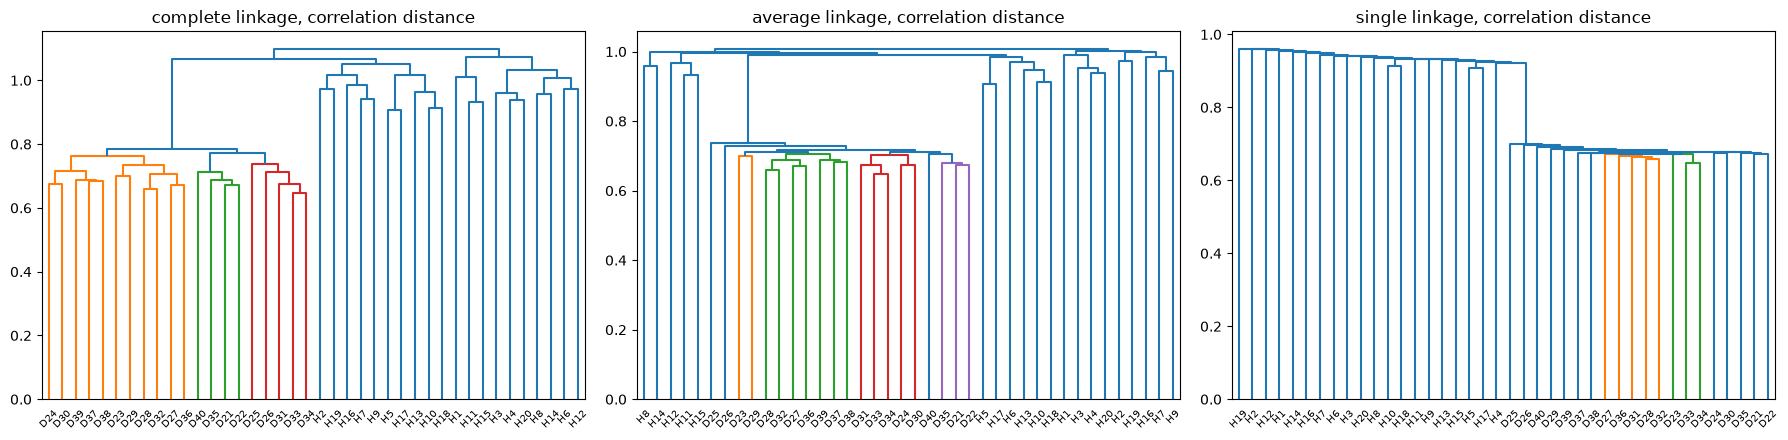

complete: ARI = 0.235; 2-cluster split = {1: {'diseased': 20, 'healthy': 10}, 2: {'diseased': 0, 'healthy': 10}}
 average: ARI = 0.188; 2-cluster split = {1: {'diseased': 20, 'healthy': 11}, 2: {'diseased': 0, 'healthy': 9}}
  single: ARI = 0.000; 2-cluster split = {1: {'diseased': 20, 'healthy': 19}, 2: {'diseased': 0, 'healthy': 1}}


In [19]:
# Exercise 13(b)
d_corr = pdist(samples, metric="correlation")     # 1 - correlation between samples
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
rows = []
for ax, method in zip(axes, ["complete", "average", "single"]):
    hc = linkage(d_corr, method=method)
    dendrogram(hc, labels=[f"{'H' if g == 'healthy' else 'D'}{i + 1}" for i, g in enumerate(group)],
               leaf_font_size=7, ax=ax)
    ax.set_title(f"{method} linkage, correlation distance")
    cut = fcluster(hc, t=2, criterion="maxclust")
    rows.append({"linkage": method, "ARI vs true groups": adjusted_rand_score(group, cut),
                 "crosstab": pd.crosstab(group, cut).to_dict()})
plt.tight_layout()
plt.show()
for r in rows:
    print(f"{r['linkage']:>8s}: ARI = {r['ARI vs true groups']:.3f}; 2-cluster split = {r['crosstab']}")

### Exercise 13(c)

Your collaborator wants to know which genes differ the most
across the two groups. Suggest a way to answer this question,
and apply it here.

Genes significant at FDR 5%: 117
Range of significant gene numbers: 11–967
...of which 100 are among genes 501-600 (all 100 of those genes significant: True)


,gene,mean diff (D - H),t,p,q (BH)
501,502,2.54446,-10.31670,0.0,0.0
588,589,2.34349,-10.02461,0.0,0.0
599,600,2.74758,-9.62341,0.0,0.0
589,590,2.20532,-8.97625,0.0,0.0
564,565,2.47082,-8.62875,0.0,0.0
550,551,2.34284,-8.01143,0.0,0.0
592,593,2.40210,-7.98432,0.0,0.0
583,584,2.60199,-7.87715,0.0,0.0
537,538,2.39198,-7.75160,0.0,0.0
568,569,1.97616,-7.71742,0.0,0.0


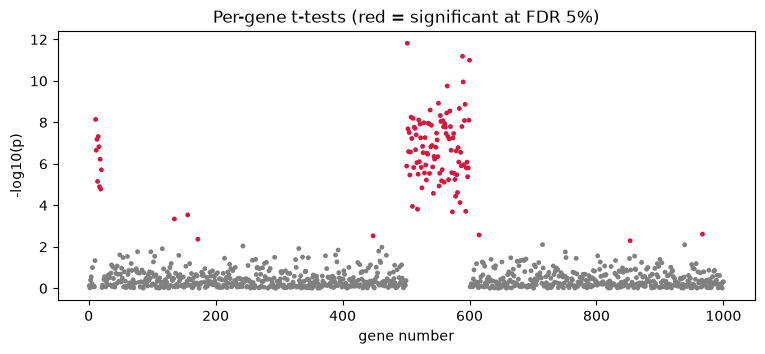

Genes with the largest |PC1 loading|: [600 584 549 540 502 582 565 568 529 599]


In [20]:
# Exercise 13(c)
# Two-sample t-test for every gene (healthy vs diseased), then control the FDR at 5%.
healthy, diseased = samples[group == "healthy"], samples[group == "diseased"]
t_stat, p_val = ttest_ind(diseased, healthy, axis=0, equal_var=False)  # t > 0 means higher in diseased
reject, q_val, _, _ = multipletests(p_val, alpha=0.05, method="fdr_bh")
res13 = pd.DataFrame({"gene": np.arange(1, 1001), "mean diff (D - H)": diseased.mean(0) - healthy.mean(0),
                      "t": t_stat, "p": p_val, "q (BH)": q_val}).sort_values("p")
print(f"Genes significant at FDR 5%: {reject.sum()}")
print(f"Range of significant gene numbers: {res13.loc[res13['q (BH)'] < 0.05, 'gene'].min()}–"
      f"{res13.loc[res13['q (BH)'] < 0.05, 'gene'].max()}")
sig_genes = res13.loc[res13["q (BH)"] < 0.05, "gene"]
print(f"...of which {sig_genes.between(501, 600).sum()} are among genes 501-600 "
      f"(all 100 of those genes significant: {set(range(501, 601)) <= set(sig_genes)})")
display(res13.head(15).round(5))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(res13["gene"], -np.log10(res13["p"]), s=6, c=np.where(res13["q (BH)"] < 0.05, "crimson", "gray"))
ax.set(xlabel="gene number", ylabel="-log10(p)", title="Per-gene t-tests (red = significant at FDR 5%)")
plt.show()

# Alternative view: loadings of the first principal component of the samples
pca13 = PCA().fit(samples)
top_load = np.argsort(np.abs(pca13.components_[0]))[::-1][:10] + 1
print("Genes with the largest |PC1 loading|:", top_load)

**Observations / conclusions**

- **(a)** The file has 1,000 rows (genes) and 40 columns (samples), so I transpose it to cluster the samples.
- **(b)** With correlation-based distance, the healthy and diseased samples do **not** separate cleanly, and the result depends heavily on the linkage. Complete linkage splits off 10 healthy samples and lumps the other 10 healthy with all 20 diseased (ARI 0.24). Average linkage is similar (ARI 0.19). Single linkage just peels off one sample (ARI 0). Correlation distance ignores overall *level* differences between samples, and a level difference in a block of genes is exactly how these groups differ, so this result isn't surprising.
- **(c)** To find which genes differ, run a **two-sample t-test for every gene** and control the false discovery rate (Benjamini–Hochberg). At FDR 5%, **117 genes** are significant. They include **all 100 genes numbered 501–600**, each about 2–2.7 units higher in the diseased group (the strongest are genes 502, 589 and 600). The other 17 are scattered elsewhere. The genes with the largest PC1 loadings (600, 584, 549, 540, 502, …) all fall in the same 501–600 block, confirming that this block is the main difference between the groups.